In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)


**Loading The Data Set**

In [33]:
df = pd.read_csv("classification_escalation.csv")
print(df.shape)
display(df.head())
print(df.info())
print(df["escalated"].value_counts(normalize=True).rename("proportion"))

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

(900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 49.8 KB
None
escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64

Missing values:
complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64


### Dataset Inspection Summary

The dataset contains 900 records and 6 columns, five predictor variables and one target variable named `escalated`.
The target variable contains two classes: 0 (not escalated) and 1 (escalated). There are 714 non-escalated tickets and 186 escalated tickets.
The dataset also contains missing values in three predictor columns: team_experience_years, priority, and customer_tenure_months.
Since the target classes are not equally distributed, accuracy alone may not be sufficient to evaluate model performance. We will therefore use additional evaluation metrics such as precision, recall, F1-score, and ROC-AUC.


## Separating Features and Target

We separate the dataset into independent variables (X) and the dependent variable (y).
- X contains the predictor features used to make predictions.
- y contains the target variable that the model is expected to predict.
The target variable is escalated.

In [34]:
X = df.drop("escalated", axis=1)
y = df["escalated"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (900, 5)
Target shape: (900,)


## Identifying Numerical and Categorical Features

We divide the predictor variables into numerical and categorical features, so that it allows us to apply different preprocessing techniques to each type of feature.

In [35]:
numeric_features = [
    "complexity_score",
    "team_experience_years",
    "customer_tenure_months"
]

categorical_features = [
    "priority",
    "channel"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['complexity_score', 'team_experience_years', 'customer_tenure_months']
Categorical features: ['priority', 'channel']


## Splitting the Dataset

We divide the dataset into training and testing sets.
We use 75% of the data for training and 25% for testing as suggested.
Stratified sampling maintains approximately the same target-class proportions in both sets.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (675, 5)
Testing features: (225, 5)

Training target distribution:
escalated
0    0.792593
1    0.207407
Name: proportion, dtype: float64

Testing target distribution:
escalated
0    0.795556
1    0.204444
Name: proportion, dtype: float64


## Data Preprocessing

Before training the models, we prepare the numerical and categorical features using separate preprocessing pipelines.

For numerical features:
- Missing values are replaced using the median.
- StandardScaler is used to standardize the values.

For categorical features:
- Missing values are replaced using the most frequent value (mode).
- OneHotEncoder converts categorical values into numerical columns.

ColumnTransformer combines the two preprocessing pipelines and applies the appropriate transformations to each feature type.

We use Pipeline to ensure that preprocessing is fitted only on the training data, preventing data leakage.


In [37]:
# Numerical preprocessing pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])


## Building Classification Models

We train four different classification models:

1. Majority-class baseline
2. Logistic Regression
3. Linear Discriminant Analysis (LDA)
4. k-Nearest Neighbors (k-NN) with k=15

The majority-class baseline provides a simple reference point by always predicting the most frequent class.
The other three models learn patterns from the training data to make predictions.
Each model is combined with the preprocessing pipeline to ensure consistent data preparation.

In [38]:
models = {
    "Majority Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Linear Discriminant Analysis": LinearDiscriminantAnalysis(),

    "k-NN (k=15)": KNeighborsClassifier(
        n_neighbors=15
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully.")


Majority Baseline trained successfully.
Logistic Regression trained successfully.
Linear Discriminant Analysis trained successfully.
k-NN (k=15) trained successfully.


## Model Evaluation and Comparison

We evaluate the trained classifiers using accuracy, precision, recall, F1-score, and ROC-AUC.
Accuracy measures the overall proportion of correct predictions.
Precision measures how many predicted positive cases are actually positive.
Recall measures how many actual positive cases are correctly identified.
F1-score is the harmonic mean of precision and recall.
ROC-AUC measures how well a model distinguishes between the positive and negative classes across different classification thresholds.
These metrics provide a more complete understanding of model performance than accuracy alone.

In [39]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, probabilities)
    else:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.7956,0.00,0.0000,0.0000,0.5000
1,Logistic Regression,0.8222,0.75,0.1957,0.3103,0.8111
2,Linear Discriminant Analysis,0.8222,0.75,0.1957,0.3103,0.8090
3,k-NN (k=15),0.7956,0.50,0.0870,0.1481,0.7046


#### Interpretation 

Logistic Regression and Linear Discriminant Analysis achieved the highest accuracy of approximately 82.22%.
Both models also achieved the highest precision and F1-score, with precision of 0.75 and F1-score of approximately 0.31.
Logistic Regression and LDA had the strongest recall, approximately 0.1957, among the evaluated classifiers.
The k-NN model achieved lower performance, with an F1-score of approximately 0.1481.
The majority-class baseline achieved 79.56% accuracy but failed to identify any escalated tickets. This demonstrates why accuracy alone can be misleading when working with imbalanced datasets.
Logistic Regression achieved the highest ROC-AUC of approximately 0.8111, indicating good ability to distinguish between the two classes.

## Confusion Matrix

A confusion matrix is used to evaluate the classification predictions by comparing actual values with predicted values.

It contains four outcomes:

- True Positive (TP): Correctly predicted escalated tickets.
- True Negative (TN): Correctly predicted non-escalated tickets.
- False Positive (FP): Non-escalated tickets incorrectly predicted as escalated.
- False Negative (FN): Escalated tickets incorrectly predicted as non-escalated.

We plot the confusion matrix for Logistic Regression using the default classification threshold of 0.50.

Confusion Matrix:
[[176   3]
 [ 37   9]]


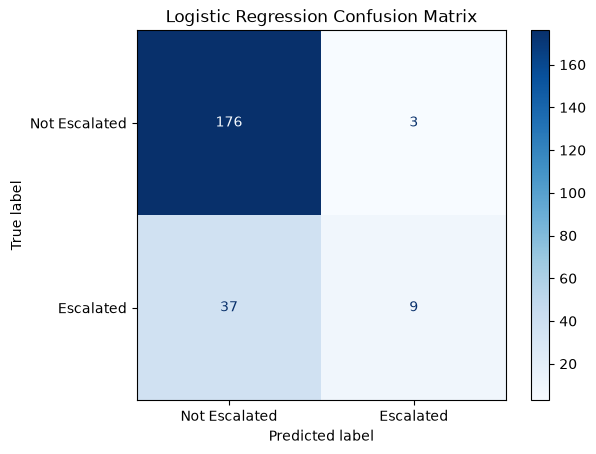

In [40]:
logistic_model = trained_models["Logistic Regression"]

y_pred_logistic = logistic_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_logistic)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Escalated", "Escalated"]
).plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")
plt.show()

## ROC Curve

The Receiver Operating Characteristic (ROC) curve illustrates the relationship between the True Positive Rate and False Positive Rate at different classification thresholds.
The Area Under the Curve (AUC) summarizes the model's ability to distinguish between positive and negative classes.
An AUC of 0.5 indicates performance similar to random guessing, while a higher AUC indicates better discrimination.

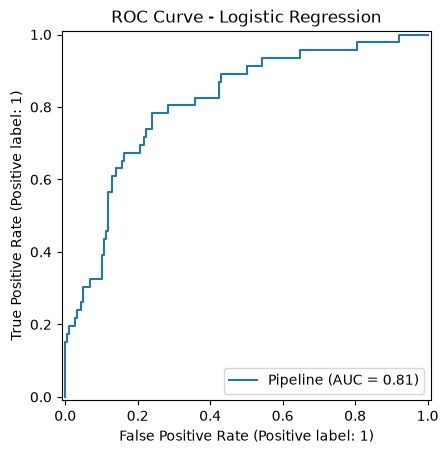

In [41]:
RocCurveDisplay.from_estimator(
    logistic_model,
    X_test,
    y_test
)

plt.title("ROC Curve - Logistic Regression")
plt.show()


## Threshold Analysis

A classification threshold determines the probability above which a ticket is classified as escalated.
By default, Logistic Regression uses a threshold of 0.50.
However, we can change this threshold to investigate its effect on precision, recall, F1-score, false positives, and false negatives.
We evaluate thresholds of 0.20, 0.30, 0.40, 0.50, 0.60, and 0.70.

In [42]:
# Get predicted probabilities
y_prob = logistic_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    y_threshold_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_threshold_pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test, y_threshold_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_threshold_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_threshold_pred, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FP": fp,
        "FN": fn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1,FP,FN
0,0.2,0.4286,0.7826,0.5538,48,10
1,0.3,0.5490,0.6087,0.5773,23,18
2,0.4,0.5714,0.2609,0.3582,9,34
3,0.5,0.7500,0.1957,0.3103,3,37
4,0.6,1.0000,0.0652,0.1224,0,43
5,0.7,0.0000,0.0000,0.0000,0,46



#### Interpretation

Lowering the classification threshold makes the model more likely to classify a ticket as escalated.
As the threshold decreases, recall generally increases because more actual escalated tickets are identified. However, false positives also increase, which can reduce precision.
At a threshold of 0.20, the model achieves a recall of approximately 0.7826, identifying 36 out of 46 escalated tickets.
At a threshold of 0.70, the model does not identify any escalated tickets.
This demonstrates that threshold selection affects the balance between identifying escalated tickets and avoiding unnecessary escalations.

## Cost-Sensitive Evaluation

The assignment provides an illustrative cost function:

Cost = 5 × FN + 1 × FP

A false negative has a cost of 5 because an escalated ticket that is missed is considered more expensive.
A false positive has a cost of 1 because incorrectly escalating a ticket has a lower cost.
We calculate the total cost for each threshold to identify the threshold that minimizes the specified cost function.

In [43]:
threshold_df["Cost"] = (
    5 * threshold_df["FN"] + threshold_df["FP"]
)

display(threshold_df.round(4))

best_threshold = threshold_df.loc[
    threshold_df["Cost"].idxmin()
]

print("\nBest threshold:")
print(best_threshold)

,Threshold,Precision,Recall,F1,FP,FN,Cost
0,0.2,0.4286,0.7826,0.5538,48,10,98
1,0.3,0.5490,0.6087,0.5773,23,18,113
2,0.4,0.5714,0.2609,0.3582,9,34,179
3,0.5,0.7500,0.1957,0.3103,3,37,188
4,0.6,1.0000,0.0652,0.1224,0,43,215
5,0.7,0.0000,0.0000,0.0000,0,46,230



Best threshold:
Threshold     0.200000
Precision     0.428571
Recall        0.782609
F1            0.553846
FP           48.000000
FN           10.000000
Cost         98.000000
Name: 0, dtype: float64



#### Interpretation

The threshold of 0.20 produces the lowest total cost of 98.
Although this threshold produces more false positives, it significantly reduces false negatives.
Since false negatives have five times the cost of false positives, reducing missed escalated tickets is more important than minimizing unnecessary escalations.
Therefore, a threshold of 0.20 is preferred under the given illustrative cost function.
However, repeatedly selecting a threshold using the test set can produce an optimistic estimate of performance. A separate validation set or cross-validation should be used for threshold selection, leaving the final test set untouched for unbiased evaluation.

## Cross-Validation and k-NN Hyperparameter Tuning

Cross-validation is used to evaluate model performance across multiple training and validation splits.
We use Stratified 5-Fold Cross-Validation to preserve the target-class proportions in each fold.
We tune the k-NN model by testing different values of k: 5, 9, 15, 21, and 31.
F1-score is used as the evaluation metric because it balances precision and recall.
GridSearchCV automatically evaluates the parameter combinations and identifies the value of k with the highest average cross-validation F1-score.

In [44]:
# Create stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create k-NN pipeline
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

# Define parameter values
param_grid = {
    "classifier__n_neighbors": [5, 9, 15, 21, 31]
}

# Perform grid search
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(grid_search.best_score_)


Best parameters:
{'classifier__n_neighbors': 5}

Best cross-validation F1-score:
0.24329611908559276


In [45]:
cv_results = pd.DataFrame(
    grid_search.cv_results_
)

display(
    cv_results[
        [
            "param_classifier__n_neighbors",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].round(4)
)


,param_classifier__n_neighbors,mean_test_score,std_test_score,rank_test_score
0,5,0.2433,0.0946,1
1,9,0.1976,0.0652,2
2,15,0.1596,0.0655,3
3,21,0.1458,0.0564,4
4,31,0.1122,0.0397,5


#### Interpretation

The best value of k is 5, which achieved the highest average cross-validation F1-score of approximately 0.2433.
The F1-score decreased as the value of k increased across the tested configurations.
This suggests that, among the tested values, using five nearest neighbors provides the best balance between precision and recall.
The result does not necessarily mean that k=5 is universally optimal, because the evaluation is limited to the selected parameter values and cross-validation setup.

## Bayesian Concepts and Cost-Sensitive Decisions

Bayes' theorem describes how prior knowledge is updated using new evidence to calculate a posterior probability.

In the ticket-escalation scenario:

- Prior: The probability that a ticket is escalated before considering its features.
- Likelihood: The probability of observing particular ticket characteristics given that the ticket is escalated.
- Evidence: The overall probability of observing those characteristics.
- Posterior: The updated probability that a ticket is escalated given its observed features.

Bayes' theorem is expressed as:

P(escalated | x) = P(x | escalated) × P(escalated) / P(x)

This probability can support decisions about whether a ticket should be escalated.


#### Cost-Sensitive Decision Threshold

Let p represent the posterior probability that a ticket is escalated.

If we escalate the ticket, the expected cost is:

Cost(escalate) = 1 × (1 - p)

If we do not escalate the ticket, the expected cost is:

Cost(not escalate) = 5 × p

We should escalate when:

1 × (1 - p) < 5 × p

1 - p < 5p

1 < 6p

p > 1/6

Therefore, the cost-sensitive classification threshold is:

Threshold = 1/6 ≈ 0.1667


### Recommendation

The recommended model and threshold should be selected by considering the evaluation metrics and the cost of classification errors.
Logistic Regression provides a useful balance of performance and interpretability. Under the illustrative cost function, a threshold of 0.20 produces the lowest observed test-set cost.
However, additional validation is necessary before deploying the model in a real customer-support environment.

# Answers to the questions

1. Why is accuracy alone potentially misleading?
   
   Accuracy can be misleading when the dataset is imbalanced. A model that predicts every ticket as not escalated achieves approximately 79.33% accuracy but fails to identify any escalated tickets. Therefore, precision, recall and F1-score are also necessary.

2. Which classifier has the strongest recall? Which has the strongest precision/F1?

   Logistic Regression and LDA tie for the strongest recall (0.1957), precision (0.75) and F1-score (0.3103) at the default threshold of 0.50.

3. What changes when the threshold is lowered?

   The model becomes more likely to classify tickets as escalated. Recall generally increases, while false positives may increase and precision may decrease.

4. Which threshold minimizes 5×FN + FP on the test set, and why might this estimate be optimistic if used repeatedly for tuning?

   The threshold of 0.20 minimizes the test-set cost, producing a total cost of 98.
The estimate may be optimistic because repeatedly selecting a threshold using the same test set can lead to overfitting to that test set.

5. Explain prior, likelihood, posterior and evidence using the ticket scenario.

- Prior: The initial probability that a ticket will be escalated.
- Likelihood: The probability of observing certain ticket characteristics given that it is escalated.
- Evidence: The overall probability of observing those characteristics.
- Posterior: The updated probability that the ticket will be escalated after considering its characteristics.

6. With posterior P(escalated|x)=0.30, false-positive cost 1 and false-negative cost 5, compare the expected cost of escalating and not escalating. Derive the cost-sensitive threshold.

   Cost of escalating: 1(1-0.30) = 0.70
   
   Cost of not escalating: 5(0.30) = 1.50
   
   Therefore, escalating is the better decision because its expected cost is lower.

7. Which model would you recommend for deployment, and what further checks are required?

   I would recommend Logistic Regression with a threshold of 0.20 under the given illustrative cost function. However, independent validation, fairness assessment, monitoring and real-world testing are necessary before deployment.

## Final Recommendation

Based on the experimental results, Logistic Regression is the preferred model for predicting ticket escalation. It achieved an accuracy of 82.22%, precision of 0.75, recall of 0.1957, F1-score of 0.3103, and ROC-AUC of 0.8111. Although Linear Discriminant Analysis achieved similar performance, Logistic Regression had a slightly higher ROC-AUC. The k-NN model with k=15 performed less effectively, achieving an F1-score of 0.1481.

However, the default classification threshold of 0.50 is not ideal for this problem because it identifies only a small proportion of escalated tickets. Since missing an escalated ticket is considered five times more expensive than incorrectly escalating a ticket, recall is particularly important.

The threshold analysis showed that 0.20 produced the lowest observed cost of 98 using the function 5 × FN + FP. At this threshold, recall increased to 0.7826, meaning the model identified 36 out of 46 escalated tickets. Although the number of false positives increased to 48, this was acceptable under the given cost structure because false negatives are more expensive. Therefore, Logistic Regression with a threshold of 0.20 is the preferred option based on the assignment's illustrative cost function.

Cross-validation was also used to tune the k-NN model. Among the tested values, k=5 achieved the highest average F1-score of approximately 0.2433.

Despite these results, several limitations must be considered. First, the dataset is synthetic and contains only 900 records, so its patterns may not represent real customer-support environments. Second, the target classes are imbalanced, which affects model performance. Third, the cost function is illustrative and may not accurately represent actual business costs. Additionally, repeatedly selecting a threshold using the test set can produce optimistic performance estimates.

Before deployment, the model should be evaluated using independent real-world data, and the threshold should be selected using a separate validation process. Further checks should include fairness assessment, data quality evaluation, performance monitoring, and periodic model updates. Human oversight should also be maintained so that important escalation decisions are not made entirely automatically.

In conclusion, Logistic Regression with a threshold of 0.20 is the preferred model for this experiment because it provides the lowest observed error cost under the specified conditions. However, further validation is required before considering real-world deployment.